# EDA: маркетплейс Capibara (Olist)

**Цель.** Провести разведочный анализ 8 CSV-файлов до проектирования DWH
(слои `raw -> core -> mart`), найти проблемы качества данных, понять
гранулярность сущностей и сформулировать инженерные и бизнес-гипотезы.

**Данные.** 8 файлов, 550 759 строк, период сентябрь 2016 — октябрь 2018.
Целевой отчётный период — сентябрь 2016 — август 2018.

**Важно.** Все исходные колонки в `raw` имеют тип `text`. В этом notebook
данные читаются как строки, а типы приводятся только в исследовательских
копиях/колонках. Схему `raw` не меняем.

**Известные ловушки:**
- `customer_id` — идентификатор заказа/строки, `customer_unique_id` — покупатель;
- `order_item_id` — порядковый номер позиции, а не идентификатор;
- `review_id` не уникален, один заказ может иметь несколько отзывов;
- у 610 товаров не заполнена категория, 2 категории без перевода;
- в названиях колонок `product_name_lenght` и `product_description_lenght`
  сохранена опечатка исходника.

## 0. Setup и загрузка данных

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


def find_data_dir():
    """Ищем папку data и из корня проекта, и из папки notebooks."""
    for candidate in (Path("data"), Path("..") / "data"):
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError("Не найдена папка data")


DATA_DIR = find_data_dir()
REPORT_START = pd.Timestamp("2016-09-01")
REPORT_END = pd.Timestamp("2018-08-31 23:59:59")

print("DATA_DIR:", DATA_DIR)
print("Отчётный период:", REPORT_START.date(), "—", REPORT_END.date())

DATA_DIR: D:\Development\WB_Hack\hackathon-students\data
Отчётный период: 2016-09-01 — 2018-08-31


## 1. Словарь данных

| Таблица | Гранулярность | Ключ | Внешние ключи | Особенности |
|---|---|---|---|---|
| `orders` | один заказ | `order_id` | `customer_id` | даты жизненного цикла, nullable-даты доставки |
| `order_items` | одна позиция заказа | `(order_id, order_item_id)` | `product_id`, `seller_id` | одна строка = один товар одного продавца; количество не хранится отдельно |
| `customers` | одна строка на `customer_id` | `customer_id` | — | `customer_unique_id` — реальный покупатель, не уникален |
| `order_payments` | один платёж | `(order_id, payment_sequential)` | `order_id` | у заказа может быть несколько платежей |
| `order_reviews` | один отзыв | `(review_id, order_id)` | `order_id` | `review_id` не уникален; у заказа бывает до 3 отзывов |
| `products` | один товар | `product_id` | — | категория, габариты, вес; есть пропуски |
| `sellers` | один продавец | `seller_id` | — | город, штат, zip |
| `product_category_translation` | одна категория | `product_category_name` | — | 71 перевод, 2 категории без перевода |

**Бизнес-смысл связей:**
- заказ принадлежит одному `customer_id`, но один человек может иметь много `customer_id`;
- в заказе может быть несколько товаров и несколько продавцов;
- оплата может быть разбита на несколько строк и способов;
- отзыв привязан к заказу, а не к позиции;
- товар относится к категории, категория переводится справочником.

In [2]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "product_category_translation": "product_category_name_translation.csv",
}


def load_tables():
    """Читаем все CSV как текст: raw-слой не должен терять исходные значения."""
    tables = {}
    total_rows = 0
    for name, filename in FILES.items():
        path = DATA_DIR / filename
        if not path.exists():
            raise FileNotFoundError(f"Нет файла: {path}")
        df = pd.read_csv(path, dtype=str, encoding="utf-8-sig", low_memory=False)
        tables[name] = df
        total_rows += len(df)
        mem_mb = df.memory_usage(deep=True).sum() / 1024**2
        print(f"{name:32s} {len(df):>8,} строк x {df.shape[1]:>2} колонок  {mem_mb:7.1f} MB")
    print(f"{'ИТОГО':32s} {total_rows:>8,} строк")
    return tables


tables = load_tables()
ORIGINAL_COLUMNS = {name: list(df.columns) for name, df in tables.items()}

orders                             99,441 строк x  8 колонок     52.9 MB
order_items                       112,650 строк x  7 колонок     50.4 MB


customers                          99,441 строк x  5 колонок     30.9 MB
order_payments                    103,886 строк x  5 колонок     29.2 MB


order_reviews                      99,224 строк x  7 колонок     43.1 MB
products                           32,951 строк x  9 колонок     15.8 MB
sellers                             3,095 строк x  4 колонок      0.7 MB
product_category_translation           71 строк x  2 колонок      0.0 MB
ИТОГО                             550,759 строк


### 1.1. Приведение типов в исследовательских колонках

Исходные строковые колонки сохраняем. Рядом добавляем разобранные даты и
числа, чтобы отдельно видеть ошибки парсинга и не портить raw-значения.

In [3]:
orders = tables["orders"]
order_items = tables["order_items"]
customers = tables["customers"]
order_payments = tables["order_payments"]
order_reviews = tables["order_reviews"]
products = tables["products"]
sellers = tables["sellers"]
translation = tables["product_category_translation"]


def to_num(series):
    return pd.to_numeric(series, errors="coerce")


def to_dt(series):
    return pd.to_datetime(series, errors="coerce")


# orders: даты жизненного цикла заказа
orders["purchase_ts"] = to_dt(orders["order_purchase_timestamp"])
orders["approved_ts"] = to_dt(orders["order_approved_at"])
orders["carrier_ts"] = to_dt(orders["order_delivered_carrier_date"])
orders["delivered_ts"] = to_dt(orders["order_delivered_customer_date"])
orders["estimated_ts"] = to_dt(orders["order_estimated_delivery_date"])

# order_items: деньги, срок отгрузки и номер позиции
order_items["price_num"] = to_num(order_items["price"])
order_items["freight_num"] = to_num(order_items["freight_value"])
order_items["total_num"] = order_items["price_num"] + order_items["freight_num"]
order_items["shipping_limit_ts"] = to_dt(order_items["shipping_limit_date"])
order_items["order_item_num"] = to_num(order_items["order_item_id"])

# order_payments: сумма платежа и число частей рассрочки
order_payments["payment_value_num"] = to_num(order_payments["payment_value"])
order_payments["installments_num"] = to_num(order_payments["payment_installments"])

# order_reviews: оценка и даты отзыва
order_reviews["review_score_num"] = to_num(order_reviews["review_score"])
order_reviews["review_creation_ts"] = to_dt(order_reviews["review_creation_date"])
order_reviews["review_answer_ts"] = to_dt(order_reviews["review_answer_timestamp"])

# products: физические характеристики
products["name_length_num"] = to_num(products["product_name_lenght"])
products["description_length_num"] = to_num(products["product_description_lenght"])
products["photos_num"] = to_num(products["product_photos_qty"])
products["weight_num"] = to_num(products["product_weight_g"])
products["length_num"] = to_num(products["product_length_cm"])
products["height_num"] = to_num(products["product_height_cm"])
products["width_num"] = to_num(products["product_width_cm"])

print("Ошибки парсинга дат:")
for raw_col, parsed_col in [
    ("order_purchase_timestamp", "purchase_ts"),
    ("order_approved_at", "approved_ts"),
    ("order_delivered_carrier_date", "carrier_ts"),
    ("order_delivered_customer_date", "delivered_ts"),
    ("order_estimated_delivery_date", "estimated_ts"),
]:
    bad = int(orders[parsed_col].isna().sum())
    print(f"  {raw_col:32s} -> {bad:>5,} NaT")

print("\nОшибки парсинга денег:")
for raw_col, parsed_col, df in [
    ("price", "price_num", order_items),
    ("freight_value", "freight_num", order_items),
    ("payment_value", "payment_value_num", order_payments),
]:
    bad = int(df[parsed_col].isna().sum())
    print(f"  {raw_col:32s} -> {bad:>5,} NaN")

Ошибки парсинга дат:
  order_purchase_timestamp         ->     0 NaT
  order_approved_at                ->   160 NaT
  order_delivered_carrier_date     -> 1,783 NaT
  order_delivered_customer_date    -> 2,965 NaT
  order_estimated_delivery_date    ->     0 NaT

Ошибки парсинга денег:
  price                            ->     0 NaN
  freight_value                    ->     0 NaN
  payment_value                    ->     0 NaN


## 2. Блок 1. Качество данных (Data Quality)

Проверяем размерности, пропуски, дубликаты, ссылочную целостность и
аномалии типов. Результат — реестр проблем и правила для слоя `core`.

### 2.1. Пропуски

In [4]:
def missing_report(df):
    """Считаем NaN и пустые/пробельные строки по каждой колонке."""
    n = len(df)
    blank = df.apply(
        lambda s: s.fillna("").astype(str).str.strip().eq("").sum()
    )
    report = pd.DataFrame(
        {
            "missing": df.isna().sum(),
            "missing_pct": (df.isna().mean() * 100).round(2),
            "blank_or_na": blank,
            "blank_or_na_pct": (blank / n * 100).round(2),
        }
    )
    report = report[(report["missing"] > 0) | (report["blank_or_na"] > 0)]
    return report.sort_values(["missing_pct", "blank_or_na"], ascending=False)


for name, df in tables.items():
    report = missing_report(df[ORIGINAL_COLUMNS[name]])
    print(f"\n### {name}: {len(report)} колонок с пропусками")
    if len(report):
        display(report)


### orders: 3 колонок с пропусками


,missing,missing_pct,blank_or_na,blank_or_na_pct
order_delivered_customer_date,2965,2.98,2965,2.98
order_delivered_carrier_date,1783,1.79,1783,1.79
order_approved_at,160,0.16,160,0.16



### order_items: 0 колонок с пропусками



### customers: 0 колонок с пропусками

### order_payments: 0 колонок с пропусками



### order_reviews: 2 колонок с пропусками


,missing,missing_pct,blank_or_na,blank_or_na_pct
review_comment_title,87656,88.34,87658,88.34
review_comment_message,58247,58.70,58274,58.73



### products: 8 колонок с пропусками


,missing,missing_pct,blank_or_na,blank_or_na_pct
product_category_name,610,1.85,610,1.85
product_name_lenght,610,1.85,610,1.85
product_description_lenght,610,1.85,610,1.85
product_photos_qty,610,1.85,610,1.85
product_weight_g,2,0.01,2,0.01
product_length_cm,2,0.01,2,0.01
product_height_cm,2,0.01,2,0.01
product_width_cm,2,0.01,2,0.01



### sellers: 0 колонок с пропусками

### product_category_translation: 0 колонок с пропусками


**Интерпретация.** Основные пропуски ожидаемы и связаны со статусом
заказа: нет подтверждения оплаты, передачи логисту или доставки.
В `products` пропуски категории и габаритов идут одним блоком — вероятно,
это товары, карточки которых заполнены не полностью. В отзывах пустой
текст — норма: оценка может быть без комментария.

### 2.2. Дубликаты и бизнес-ключи

In [5]:
DUP_KEYS = {
    "orders": ["order_id"],
    "order_items": [["order_id", "order_item_id"]],
    "customers": ["customer_id", "customer_unique_id"],
    "order_payments": [["order_id", "payment_sequential"]],
    "order_reviews": ["review_id", ["review_id", "order_id"], "order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "product_category_translation": ["product_category_name"],
}


def duplicate_report(df, keys):
    checks = ["полная строка"] + [
        "+".join(k) if isinstance(k, list) else k for k in keys
    ]
    dup_rows = [int(df.duplicated().sum())] + [
        int(df.duplicated(subset=k).sum()) for k in keys
    ]
    unique_keys = [int(df.drop_duplicates().shape[0])] + [
        int(df.drop_duplicates(subset=k).shape[0]) for k in keys
    ]
    return pd.DataFrame(
        {
            "проверка": checks,
            "дублирующихся_строк": dup_rows,
            "уникальных_ключей": unique_keys,
        }
    )


for name, keys in DUP_KEYS.items():
    print(f"\n### {name}")
    display(duplicate_report(tables[name], keys))


### orders


,проверка,дублирующихся_строк,уникальных_ключей
0,полная строка,0,99441
1,order_id,0,99441



### order_items


,проверка,дублирующихся_строк,уникальных_ключей
0,полная строка,0,112650
1,order_id+order_item_id,0,112650



### customers


...

,проверка,дублирующихся_строк,уникальных_ключей
0,полная строка,0,32951
1,product_id,0,32951



### sellers


,проверка,дублирующихся_строк,уникальных_ключей
0,полная строка,0,3095
1,seller_id,0,3095



### product_category_translation


,проверка,дублирующихся_строк,уникальных_ключей
0,полная строка,0,71
1,product_category_name,0,71


**Интерпретация.**
- Полных дублей нет.
- `customer_unique_id` повторяется закономерно: это реальный покупатель,
  у которого несколько заказов/`customer_id`.
- `review_id` не уникален: 814 строк имеют повторяющийся `review_id`,
  но пара `(review_id, order_id)` уникальна. Для DWH нужен составной ключ
  или суррогатный ключ отзыва.
- Один заказ может иметь несколько отзывов, поэтому при расчёте метрик
  на уровне заказа нужна дедупликация.

### 2.3. Ссылочная целостность

In [6]:
def anti_join_count(child, child_key, parent, parent_key):
    """Сколько строк child не нашли пару в parent."""
    return int((~child[child_key].isin(parent[parent_key])).sum())


ri_checks = [
    ("order_items -> orders", order_items, "order_id", orders, "order_id"),
    ("order_payments -> orders", order_payments, "order_id", orders, "order_id"),
    ("order_reviews -> orders", order_reviews, "order_id", orders, "order_id"),
    ("order_items -> products", order_items, "product_id", products, "product_id"),
    ("order_items -> sellers", order_items, "seller_id", sellers, "seller_id"),
    ("orders -> customers", orders, "customer_id", customers, "customer_id"),
    ("customers -> orders", customers, "customer_id", orders, "customer_id"),
]

ri_rows = []
for label, child, child_key, parent, parent_key in ri_checks:
    bad = anti_join_count(child, child_key, parent, parent_key)
    ri_rows.append(
        {
            "проверка": label,
            "сиротских_строк": bad,
            "доля_pct": round(bad / len(child) * 100, 4) if len(child) else 0.0,
        }
    )

ri = pd.DataFrame(ri_rows)
display(ri)

product_categories = set(products["product_category_name"].dropna())
translated_categories = set(translation["product_category_name"].dropna())
missing_translation = sorted(product_categories - translated_categories)
print("Категории без перевода:", missing_translation)
print("Количество категорий в products:", len(product_categories))
print("Количество категорий в translation:", len(translated_categories))

,проверка,сиротских_строк,доля_pct
0,order_items -> orders,0,0.00
1,order_payments -> orders,0,0.00
2,order_reviews -> orders,0,0.00
3,order_items -> products,0,0.00
4,order_items -> sellers,0,0.00
5,orders -> customers,0,0.00
6,customers -> orders,0,0.00


Категории без перевода: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Количество категорий в products: 73
Количество категорий в translation: 71


**Интерпретация.** Сиротских строк нет: все позиции, платежи и отзывы
ссылаются на существующие заказы, товары и продавцов. Это хорошая новость
для ETL: `JOIN` в `core` не должен молча терять строки, но проверять
счётчики до/после соединений всё равно нужно.

Отдельно есть разрыв в справочнике категорий: 2 португальские категории
не имеют английского перевода. Для DWH нужен `unknown`/fallback-перевод.

### 2.4. Аномалии дат и числовых значений

In [7]:
print("Диапазон дат покупки:")
print("  min:", orders["purchase_ts"].min())
print("  max:", orders["purchase_ts"].max())

interval_checks = [
    ("approved_at < purchase", "approved_ts", "purchase_ts"),
    ("carrier_date < approved_at", "carrier_ts", "approved_ts"),
    ("delivered_customer_date < carrier_date", "delivered_ts", "carrier_ts"),
    ("delivered_customer_date < purchase", "delivered_ts", "purchase_ts"),
]

print("\nОтрицательные интервалы жизненного цикла:")
for label, later_col, earlier_col in interval_checks:
    valid = orders[later_col].notna() & orders[earlier_col].notna()
    bad = int((orders.loc[valid, later_col] < orders.loc[valid, earlier_col]).sum())
    print(f"  {label:48s} {bad:>5,}")

late_mask = orders["delivered_ts"].notna() & orders["estimated_ts"].notna()
late = orders.loc[late_mask, "delivered_ts"] > orders.loc[late_mask, "estimated_ts"]
late_days = (
    orders.loc[late_mask, "delivered_ts"] - orders.loc[late_mask, "estimated_ts"]
).dt.days
print("\nДоставка позже обещанной даты:")
print("  опозданий:", int(late.sum()), f"({late.mean() * 100:.2f}% от доставленных)")
print("  квантили дней опоздания:", late_days.quantile([0, 0.5, 0.9, 0.99, 1]).to_dict())

delivered_without_date = int(
    ((orders["order_status"] == "delivered") & orders["delivered_ts"].isna()).sum()
)
print("  delivered без даты вручения:", delivered_without_date)

print("\nЧисловые аномалии:")
print("  price <= 0:", int((order_items["price_num"] <= 0).sum()))
print("  freight < 0:", int((order_items["freight_num"] < 0).sum()))
print("  payment_value <= 0:", int((order_payments["payment_value_num"] <= 0).sum()))
print("  installments <= 0:", int((order_payments["installments_num"] <= 0).sum()))
print(
    "  review_score вне 1..5:",
    int(
        (
            order_reviews["review_score_num"].notna()
            & ~order_reviews["review_score_num"].between(1, 5)
        ).sum()
    ),
)

print("\nФизические характеристики товаров:")
for col in ["weight_num", "length_num", "height_num", "width_num"]:
    s = products[col]
    print(
        f"  {col:14s} <=0: {int((s <= 0).sum()):>4}  "
        f"min={s.min():>10.2f}  median={s.median():>10.2f}  max={s.max():>12.2f}"
    )

Диапазон дат покупки:
  min: 2016-09-04 21:15:19
  max: 2018-10-17 17:30:18

Отрицательные интервалы жизненного цикла:
  approved_at < purchase                               0


  carrier_date < approved_at                       1,359
  delivered_customer_date < carrier_date              23
  delivered_customer_date < purchase                   0

Доставка позже обещанной даты:
  опозданий: 7827 (8.11% от доставленных)
  квантили дней опоздания: {0.0: -147.0, 0.5: -12.0, 0.9: -2.0, 0.99: 18.0, 1.0: 188.0}
  delivered без даты вручения: 8

Числовые аномалии:
  price <= 0: 0
  freight < 0: 0
  payment_value <= 0: 9
  installments <= 0: 2
  review_score вне 1..5: 0

Физические характеристики товаров:
  weight_num     <=0:    4  min=      0.00  median=    700.00  max=    40425.00
  length_num     <=0:    0  min=      7.00  median=     25.00  max=      105.00
  height_num     <=0:    0  min=      2.00  median=     13.00  max=      105.00
  width_num      <=0:    0  min=      6.00  median=     20.00  max=      118.00


**Интерпретация.**
- Даты в основном согласованы: доставка не раньше покупки, подтверждение
  оплаты не раньше покупки. Но есть 1 359 случаев передачи логисту раньше
  подтверждения оплаты и 23 случая вручения раньше передачи логисту —
  это кандидаты на очистку/ручную проверку в `core`.
- 7 827 доставок (8,11% от доставленных) пришли позже обещанной даты.
- 2 платежа имеют `payment_installments = 0` — аномалия, которую нужно
  трактовать как 1 или `unknown`.
- У 610 товаров нет категории; это не должно ронять загрузку, нужен
  `unknown`-член измерения.

## 3. Блок 2. Заказы и воронка статусов

,заказов,доля_pct
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


,нет_одобрения,нет_передачи_логисту,нет_вручения
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


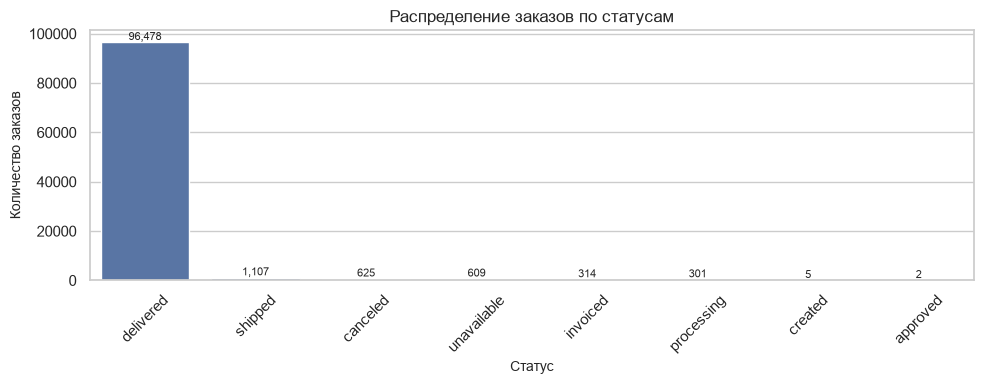

In [8]:
status_counts = orders["order_status"].value_counts()
status_table = pd.DataFrame(
    {
        "заказов": status_counts,
        "доля_pct": (status_counts / len(orders) * 100).round(2),
    }
)
display(status_table)

nulls_by_status = (
    orders.groupby("order_status")[["approved_ts", "carrier_ts", "delivered_ts"]]
    .apply(lambda d: d.isna().sum())
)
nulls_by_status.columns = ["нет_одобрения", "нет_передачи_логисту", "нет_вручения"]
display(nulls_by_status)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=status_counts.index, y=status_counts.values, ax=ax)
ax.set_title("Распределение заказов по статусам")
ax.set_xlabel("Статус")
ax.set_ylabel("Количество заказов")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(status_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### 3.1. Месячная динамика и пропущенные месяцы

Месяцев в отчётном периоде: 24
Месяцев с нулём заказов: 1
2016-09       4
2016-10     324
2016-11       0
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
Freq: M


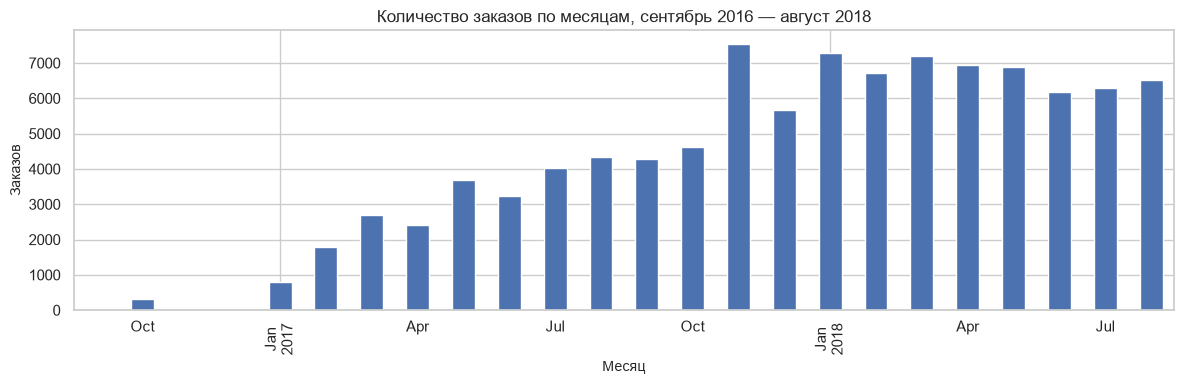

In [9]:
orders["purchase_month"] = orders["purchase_ts"].dt.to_period("M")
month_index = pd.period_range("2016-09", "2018-08", freq="M")

monthly_orders = (
    orders.loc[orders["purchase_ts"].between(REPORT_START, REPORT_END)]
    .groupby("purchase_month")["order_id"]
    .nunique()
    .reindex(month_index, fill_value=0)
)

print("Месяцев в отчётном периоде:", len(monthly_orders))
print("Месяцев с нулём заказов:", int((monthly_orders == 0).sum()))
print(monthly_orders.to_string())

fig, ax = plt.subplots(figsize=(12, 4))
monthly_orders.plot(kind="bar", ax=ax, color="#4c72b0")
ax.set_title("Количество заказов по месяцам, сентябрь 2016 — август 2018")
ax.set_xlabel("Месяц")
ax.set_ylabel("Заказов")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

### 3.2. Сроки доставки и опоздания

,count,mean,std,min,10%,50%,90%,99%,max
delivery_days,"96,476.00",12.09,9.55,0.00,4.00,10.00,23.00,46.00,209.00
delay_days,"96,476.00",-11.88,10.18,-147.00,-22.00,-12.00,-2.00,18.00,188.00


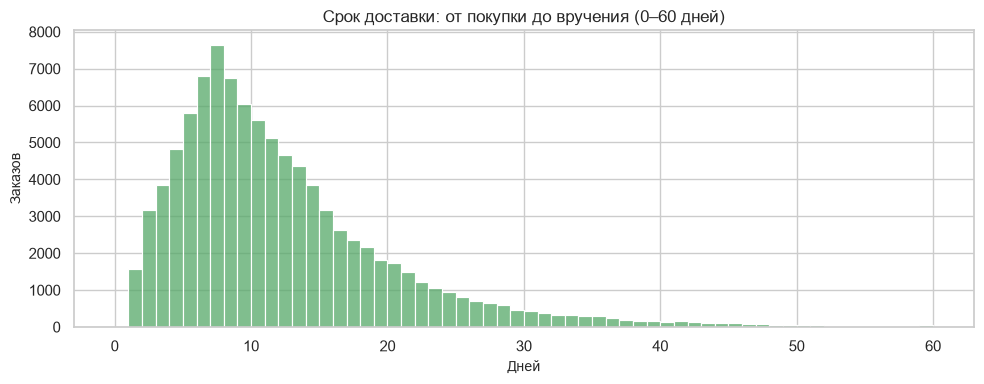

Доставленных заказов в отчётном периоде: 96478


In [10]:
orders["delivery_days"] = (orders["delivered_ts"] - orders["purchase_ts"]).dt.days
orders["delay_days"] = (orders["delivered_ts"] - orders["estimated_ts"]).dt.days

display(
    orders[["delivery_days", "delay_days"]]
    .describe(percentiles=[0.1, 0.5, 0.9, 0.99])
    .T
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(
    orders.loc[orders["delivery_days"].between(0, 60), "delivery_days"],
    bins=60,
    ax=ax,
    color="#55a868",
)
ax.set_title("Срок доставки: от покупки до вручения (0–60 дней)")
ax.set_xlabel("Дней")
ax.set_ylabel("Заказов")
plt.tight_layout()
plt.show()

delivered_ids = set(
    orders.loc[
        (orders["order_status"] == "delivered")
        & orders["purchase_ts"].between(REPORT_START, REPORT_END),
        "order_id",
    ]
)
print("Доставленных заказов в отчётном периоде:", len(delivered_ids))

**Интерпретация по заказам.**
- 96 478 заказов (97,0%) имеют статус `delivered`; остальные статусы —
  небольшая, но важная часть воронки. Для выручки берём только `delivered`.
- Пропуски дат объясняются статусом: у `canceled`, `unavailable`,
  `processing` нет доставки. `estimated_delivery_date` заполнена всегда.
- Ноябрь 2016 отсутствует в данных полностью; декабрь 2016 — 1 заказ.
  В отчёте за 24 месяца ноябрь 2016 должен появиться с нулём, иначе
  аналитик может неверно интерпретировать динамику.
- 8,11% доставок опоздали. Это достаточно большая доля, чтобы проверить
  связь с оценками и географией.

## 4. Блок 3. Клиенты и повторные покупки

Строк в customers: 99441
Уникальных customer_id: 99441
Уникальных customer_unique_id: 96096



Покупателей: 96096
Повторных покупателей: 2997
Доля повторных: 3.12%
Максимум заказов на покупателя: 17


,покупателей
order_id,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


,customers,repeat_customers,avg_orders,repeat_rate_pct
customer_state,,,,
SP,40302,1296,1.04,3.22
RJ,12384,421,1.04,3.40
MG,11259,338,1.03,3.00
RS,5277,167,1.04,3.16
PR,4882,145,1.03,2.97
SC,3534,95,1.03,2.69
BA,3277,93,1.03,2.84
DF,2075,62,1.03,2.99
ES,1964,57,1.04,2.90


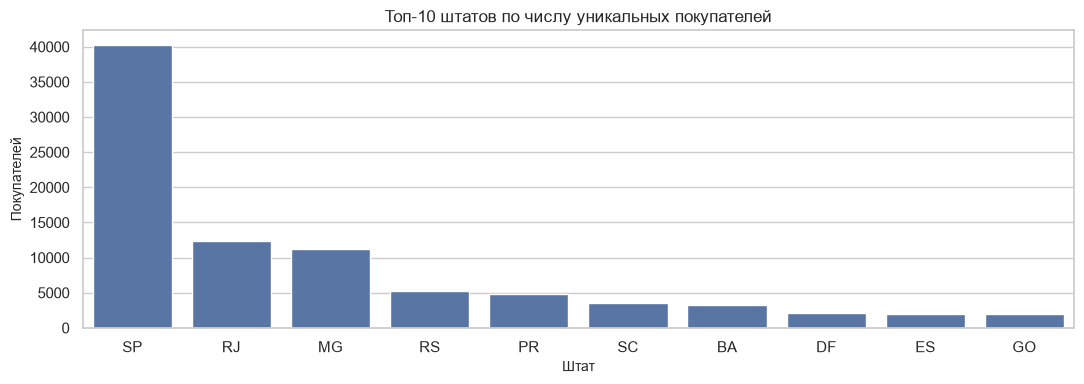

In [11]:
print("Строк в customers:", len(customers))
print("Уникальных customer_id:", customers["customer_id"].nunique())
print("Уникальных customer_unique_id:", customers["customer_unique_id"].nunique())

customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
    on="customer_id",
    how="left",
)

orders_per_customer = (
    customer_orders.groupby("customer_unique_id")["order_id"].nunique()
)
repeat_customers = int((orders_per_customer > 1).sum())
repeat_share = repeat_customers / len(orders_per_customer) * 100

print("\nПокупателей:", len(orders_per_customer))
print("Повторных покупателей:", repeat_customers)
print(f"Доля повторных: {repeat_share:.2f}%")
print("Максимум заказов на покупателя:", int(orders_per_customer.max()))

display(orders_per_customer.value_counts().sort_index().head(10).to_frame("покупателей"))

state_customer = (
    customer_orders.groupby(["customer_state", "customer_unique_id"])["order_id"]
    .nunique()
    .rename("orders")
    .reset_index()
)
state_stats = state_customer.groupby("customer_state").agg(
    customers=("customer_unique_id", "nunique"),
    repeat_customers=("orders", lambda s: int((s > 1).sum())),
    avg_orders=("orders", "mean"),
)
state_stats["repeat_rate_pct"] = (
    state_stats["repeat_customers"] / state_stats["customers"] * 100
).round(2)
state_stats = state_stats.sort_values("customers", ascending=False)

display(state_stats.head(10))

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(
    x=state_stats.head(10).index,
    y=state_stats.head(10)["customers"].values,
    ax=ax,
)
ax.set_title("Топ-10 штатов по числу уникальных покупателей")
ax.set_xlabel("Штат")
ax.set_ylabel("Покупателей")
plt.tight_layout()
plt.show()

**Интерпретация по клиентам.**
- В таблице 99 441 `customer_id`, но только 96 096 реальных покупателей:
  `customer_id` фактически уникален для заказа, поэтому считать повторные
  покупки по нему нельзя — получится 0%.
- Повторных покупателей 2 997, или 3,12%. Это низкий repeat rate;
  основная масса клиентов совершает одну покупку.
- Для DWH ключ покупателя — `customer_unique_id`, а `customer_id` —
  технический ключ заказа/строки.

## 5. Блок 4. Позиции заказа и мульти-вендорность

Позиций всего: 112650
Заказов с позициями: 98666


,count,mean,std,min,25%,50%,75%,max
items,"98,666.00",1.14,0.54,1.00,1.00,1.00,1.00,21.00
sellers,"98,666.00",1.01,0.12,1.00,1.00,1.00,1.00,5.00
revenue,"98,666.00",137.75,210.65,0.85,45.90,86.90,149.90,"13,440.00"
freight,"98,666.00",22.87,21.83,0.00,13.85,17.18,24.06,"1,794.96"



Распределение числа продавцов в заказе:


,заказов
sellers,
1,97388
2,1219
3,54
4,3
5,2


Заказов с несколькими продавцами: 1278
Доля от заказов с позициями: 1.30%
Максимум продавцов в одном заказе: 5
Заказов с разрывами/сдвигом order_item_id: 0


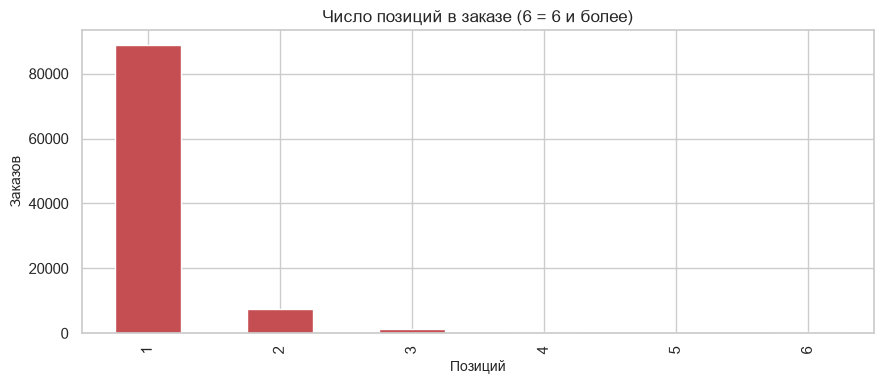

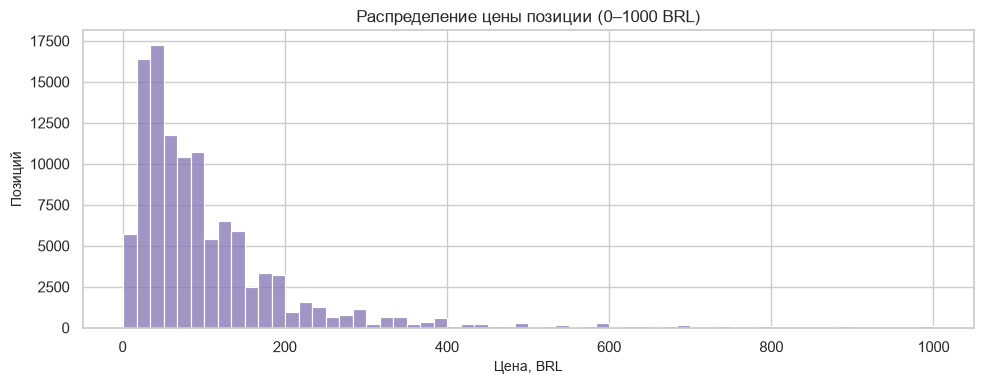

In [12]:
items_per_order = order_items.groupby("order_id").agg(
    items=("order_item_id", "size"),
    sellers=("seller_id", "nunique"),
    revenue=("price_num", "sum"),
    freight=("freight_num", "sum"),
)
items_per_order["units"] = items_per_order["items"]

print("Позиций всего:", len(order_items))
print("Заказов с позициями:", len(items_per_order))
display(items_per_order[["items", "sellers", "revenue", "freight"]].describe().T)

print("\nРаспределение числа продавцов в заказе:")
display(items_per_order["sellers"].value_counts().sort_index().to_frame("заказов"))

multi_seller_orders = int((items_per_order["sellers"] > 1).sum())
print("Заказов с несколькими продавцами:", multi_seller_orders)
print("Доля от заказов с позициями:", f"{multi_seller_orders / len(items_per_order) * 100:.2f}%")
print("Максимум продавцов в одном заказе:", int(items_per_order["sellers"].max()))

item_sequence = (
    order_items.groupby("order_id")["order_item_num"]
    .agg(min_no="min", max_no="max", rows="size")
)
sequence_gaps = item_sequence[
    (item_sequence["min_no"] != 1)
    | (item_sequence["max_no"] != item_sequence["rows"])
]
print("Заказов с разрывами/сдвигом order_item_id:", len(sequence_gaps))

fig, ax = plt.subplots(figsize=(9, 4))
items_per_order["items"].clip(upper=6).value_counts().sort_index().plot(
    kind="bar", ax=ax, color="#c44e52"
)
ax.set_title("Число позиций в заказе (6 = 6 и более)")
ax.set_xlabel("Позиций")
ax.set_ylabel("Заказов")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(
    order_items.loc[order_items["price_num"].between(0, 1000), "price_num"],
    bins=60,
    ax=ax,
    color="#8172b2",
)
ax.set_title("Распределение цены позиции (0–1000 BRL)")
ax.set_xlabel("Цена, BRL")
ax.set_ylabel("Позиций")
plt.tight_layout()
plt.show()

**Интерпретация по позициям.**
- В среднем 1,14 позиции на заказ; большинство заказов — однопозиционные.
- 1 278 заказов (1,30%) содержат товары разных продавцов. Для выручки
  продавца нельзя брать всю сумму заказа — только его позиции.
- `order_item_id` — последовательный номер внутри заказа. Разрывы нужно
  проверить, но использовать его как идентификатор нельзя.
- Цены и доставка имеют длинный правый хвост; для средних и медиан
  лучше считать разные метрики и не смешивать уровни заказа и позиции.

## 6. Блок 5. Платежи и сверка с позициями

,платежей
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


,платежей
installments_num,
0,2
1,52543
2,12413
3,10461
4,7098
5,5239
6,3920
7,1626
8,4268


Заказов с несколькими платежами: 2961
Доля от заказов с платежами: 2.98%

Сверка платежей и позиций на уровне заказа:
  заказов в сверке: 99441
  расхождений > 0.01: 1218
  доля расхождений: 1.22%
  суммарные платежи: 16,008,872.12
  суммарные позиции + доставка: 15,848,243.14
  суммарная разница: 160,628.98
  квантили разницы: {0.0: -336.93, 0.01: -0.0, 0.5: 0.0, 0.99: 1.83, 1.0: 3782.19}


,orders,diff_sum
order_status,,
unavailable,603,"124,339.02"
delivered,440,"-2,001.39"
canceled,163,"37,369.88"
created,5,688.10
shipped,4,84.63
invoiced,3,149.24


Заказов без позиций: 775
  из них с положительным платежом: 772
  из них с нулевым платежом: 3
Заказов с позициями и нулевым платежом: 1
Заказов без строк платежей: 1


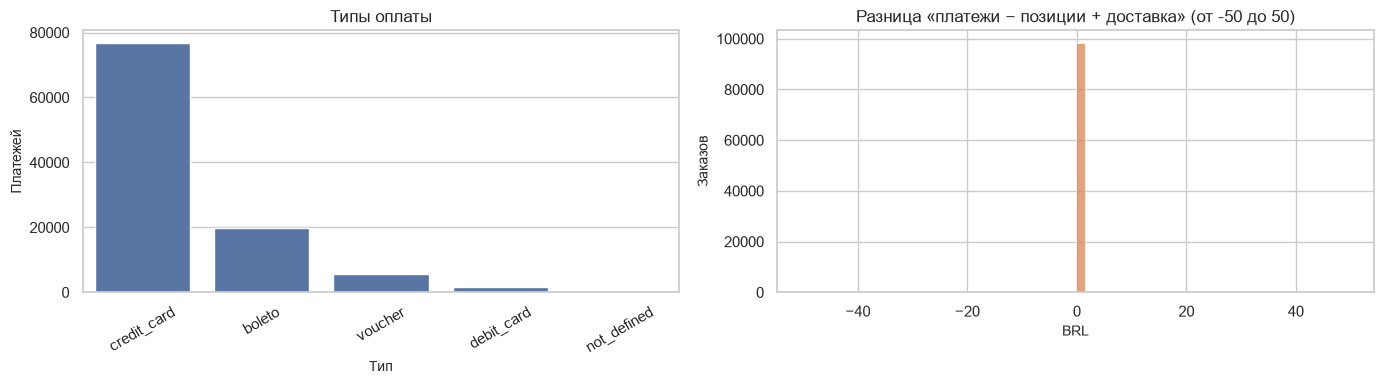

In [13]:
payment_type_counts = order_payments["payment_type"].value_counts()
display(payment_type_counts.to_frame("платежей"))

installments = order_payments["installments_num"].value_counts().sort_index()
display(installments.head(15).to_frame("платежей"))

pay_per_order = order_payments.groupby("order_id").agg(
    payments=("payment_sequential", "size"),
    pay_total=("payment_value_num", "sum"),
    payment_types=("payment_type", "nunique"),
    max_installments=("installments_num", "max"),
)
print("Заказов с несколькими платежами:", int((pay_per_order["payments"] > 1).sum()))
print(
    "Доля от заказов с платежами:",
    f"{(pay_per_order['payments'] > 1).mean() * 100:.2f}%",
)

item_totals = order_items.groupby("order_id").agg(
    items_total=("total_num", "sum"),
    item_rows=("order_item_id", "size"),
)
recon = pay_per_order[["pay_total"]].join(item_totals, how="outer").fillna(0)
recon["diff"] = recon["pay_total"] - recon["items_total"]
recon["mismatch"] = recon["diff"].abs() > 0.01

print("\nСверка платежей и позиций на уровне заказа:")
print("  заказов в сверке:", len(recon))
print("  расхождений > 0.01:", int(recon["mismatch"].sum()))
print("  доля расхождений:", f"{recon['mismatch'].mean() * 100:.2f}%")
print("  суммарные платежи:", f"{recon['pay_total'].sum():,.2f}")
print("  суммарные позиции + доставка:", f"{recon['items_total'].sum():,.2f}")
print("  суммарная разница:", f"{recon['diff'].sum():,.2f}")
print("  квантили разницы:", recon["diff"].quantile([0, 0.01, 0.5, 0.99, 1]).round(2).to_dict())

recon_status = recon.join(orders.set_index("order_id")["order_status"], how="left")
mismatch_by_status = (
    recon_status.loc[recon_status["mismatch"]]
    .groupby("order_status")
    .agg(orders=("diff", "size"), diff_sum=("diff", "sum"))
    .sort_values("orders", ascending=False)
)
display(mismatch_by_status)

no_items_total = int((recon["items_total"] == 0).sum())
no_items_positive = int(((recon["items_total"] == 0) & (recon["pay_total"] > 0)).sum())
no_items_zero = int(((recon["items_total"] == 0) & (recon["pay_total"] == 0)).sum())
no_payment = int(((recon["pay_total"] == 0) & (recon["items_total"] > 0)).sum())
no_payment_rows = len(set(orders["order_id"]) - set(order_payments["order_id"]))
print("Заказов без позиций:", no_items_total)
print("  из них с положительным платежом:", no_items_positive)
print("  из них с нулевым платежом:", no_items_zero)
print("Заказов с позициями и нулевым платежом:", no_payment)
print("Заказов без строк платежей:", no_payment_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(
    x=payment_type_counts.index,
    y=payment_type_counts.values,
    ax=axes[0],
)
axes[0].set_title("Типы оплаты")
axes[0].set_xlabel("Тип")
axes[0].set_ylabel("Платежей")
axes[0].tick_params(axis="x", rotation=30)

sns.histplot(
    recon.loc[recon["diff"].between(-50, 50), "diff"],
    bins=60,
    ax=axes[1],
    color="#dd8452",
)
axes[1].set_title("Разница «платежи − позиции + доставка» (от -50 до 50)")
axes[1].set_xlabel("BRL")
axes[1].set_ylabel("Заказов")
plt.tight_layout()
plt.show()

**Интерпретация по платежам.**
- Основной способ оплаты — кредитная карта; далее boleto, voucher,
  debit_card. Есть 3 платежа `not_defined`.
- Рассрочка бывает до 24 частей; есть 2 платежа с `installments = 0`.
- В 1 218 заказах (1,22%) сумма платежей не совпадает с суммой позиций
  и доставки больше чем на копейку. Суммарная разница 160 628,98 BRL.
  Это не обязательно ошибка: ваучеры, округления, отмены и разные
  моменты фиксации платежей. Но для DWH нужно явно определить, какая
  сумма является «выручкой», а какая — «оплатой».
- 775 заказов не имеют позиций: у 772 есть положительный платёж, у 3 —
  нулевой. Один заказ с позициями не имеет строк платежей. Такие заказы
  нельзя терять при JOIN.

**Важно для метрик:**
- выручка в контрольных вопросах = `SUM(price)` по доставленным заказам;
- средний чек = `SUM(price + freight_value) / количество доставленных заказов`;
- сумма оплат = `SUM(payment_value)` — это отдельная метрика.

## 7. Блок 6. Отзывы и связь с задержкой доставки

,отзывов
review_score_num,
1,11424
2,3151
3,8179
4,19142
5,57328


Всего отзывов: 99224
Уникальных заказов с отзывом: 98673
Заказов всего: 99441
Покрытие отзывами: 99.23%
Дубли review_id: 814
Дубли (review_id, order_id): 0
Заказов с более чем одним отзывом: 547


Максимум отзывов на заказ: 3

Пропуски текста отзыва:


,пропусков_pct
review_comment_title,88.34
review_comment_message,58.70


Отзывов после дедупликации по order_id: 98673



Средняя оценка при опоздании: 2.27
Средняя оценка вовремя: 4.29
Разница: -2.02
Spearman correlation(delay_days, review_score): -0.176


,reviews,mean_score
delay_bucket,,
>7 дней раньше,75744,4.31
-7..0,13699,4.17
1..3,1852,3.29
4..7,1748,2.10
8..15,1601,1.67
>15,1180,1.73


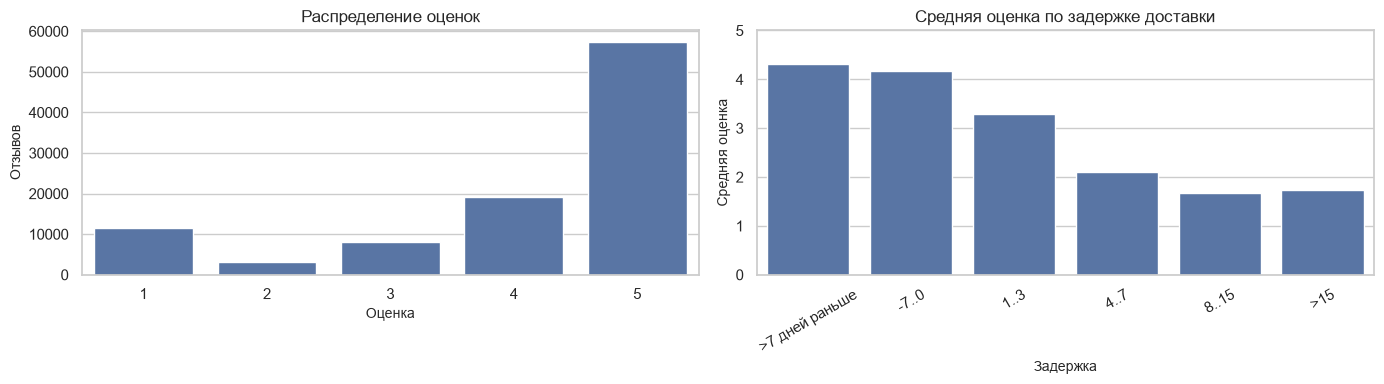

In [14]:
review_scores = order_reviews["review_score_num"].value_counts().sort_index()
display(review_scores.to_frame("отзывов"))

print("Всего отзывов:", len(order_reviews))
print("Уникальных заказов с отзывом:", order_reviews["order_id"].nunique())
print("Заказов всего:", len(orders))
print("Покрытие отзывами:", f"{order_reviews['order_id'].nunique() / len(orders) * 100:.2f}%")
print("Дубли review_id:", int(order_reviews.duplicated("review_id").sum()))
print("Дубли (review_id, order_id):", int(order_reviews.duplicated(["review_id", "order_id"]).sum()))
print("Заказов с более чем одним отзывом:", int((order_reviews.groupby("order_id").size() > 1).sum()))
print("Максимум отзывов на заказ:", int(order_reviews.groupby("order_id").size().max()))
print("\nПропуски текста отзыва:")
display((order_reviews[["review_comment_title", "review_comment_message"]].isna().mean() * 100).round(2).to_frame("пропусков_pct"))

# Для связи с доставкой оставляем один отзыв на заказ: последний по времени ответа.
reviews_dedup = (
    order_reviews.sort_values("review_answer_ts")
    .drop_duplicates("order_id", keep="last")
)
print("Отзывов после дедупликации по order_id:", len(reviews_dedup))

reviews_delivered = reviews_dedup.merge(
    orders[["order_id", "order_status", "purchase_ts", "delivered_ts", "estimated_ts"]],
    on="order_id",
    how="inner",
)
reviews_delivered = reviews_delivered.loc[
    (reviews_delivered["order_status"] == "delivered")
    & reviews_delivered["delivered_ts"].notna()
    & reviews_delivered["estimated_ts"].notna()
].copy()
reviews_delivered["delay_days"] = (
    reviews_delivered["delivered_ts"] - reviews_delivered["estimated_ts"]
).dt.days
reviews_delivered["late"] = reviews_delivered["delay_days"] > 0

late_score = reviews_delivered.loc[reviews_delivered["late"], "review_score_num"].mean()
ontime_score = reviews_delivered.loc[~reviews_delivered["late"], "review_score_num"].mean()
print("\nСредняя оценка при опоздании:", round(late_score, 3))
print("Средняя оценка вовремя:", round(ontime_score, 3))
print(
    "Разница:",
    round(late_score - ontime_score, 3),
)
corr = reviews_delivered[["delay_days", "review_score_num"]].corr(method="spearman").iloc[0, 1]
print("Spearman correlation(delay_days, review_score):", round(corr, 3))

delay_bins = [-999, -7, 0, 3, 7, 15, 999]
delay_labels = [">7 дней раньше", "-7..0", "1..3", "4..7", "8..15", ">15"]
reviews_delivered["delay_bucket"] = pd.cut(
    reviews_delivered["delay_days"],
    bins=delay_bins,
    labels=delay_labels,
)
delay_stats = reviews_delivered.groupby("delay_bucket", observed=True).agg(
    reviews=("review_score_num", "size"),
    mean_score=("review_score_num", "mean"),
)
delay_stats["mean_score"] = delay_stats["mean_score"].round(3)
display(delay_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(
    x=review_scores.index.astype(int),
    y=review_scores.values,
    ax=axes[0],
)
axes[0].set_title("Распределение оценок")
axes[0].set_xlabel("Оценка")
axes[0].set_ylabel("Отзывов")

sns.barplot(
    x=delay_stats.index,
    y=delay_stats["mean_score"].values,
    ax=axes[1],
    color="#4c72b0",
)
axes[1].set_title("Средняя оценка по задержке доставки")
axes[1].set_xlabel("Задержка")
axes[1].set_ylabel("Средняя оценка")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, 5)
plt.tight_layout()
plt.show()

**Интерпретация по отзывам.**
- Оценки смещены в высокую сторону: 5 — самая частая, но 1–2 встречаются
  достаточно часто, чтобы их анализировать.
- Покрытие отзывами — 98 673 заказа из 99 441 (99,2%).
- При опоздании средняя оценка заметно ниже, чем при доставке вовремя.
  Это подтверждает гипотезу о влиянии логистики на удовлетворённость.
- Для DWH: `(review_id, order_id)` — уникальный ключ; если нужна одна
  оценка на заказ, берём последний отзыв по `review_answer_timestamp`.

## 8. Блок 7. Товары и категории

Товаров: 32951
Без категории: 610
Доля без категории: 1.85%
Уникальных категорий в products: 73
Категорий в переводе: 71

Категорий в выручке: 74
Сумма выручки по категориям: 13,221,498.11
Топ-5:


,revenue
category,
health_beauty,"1,233,131.72"
watches_gifts,"1,166,176.98"
bed_bath_table,"1,023,434.76"
sports_leisure,"954,852.55"
computers_accessories,"888,724.61"


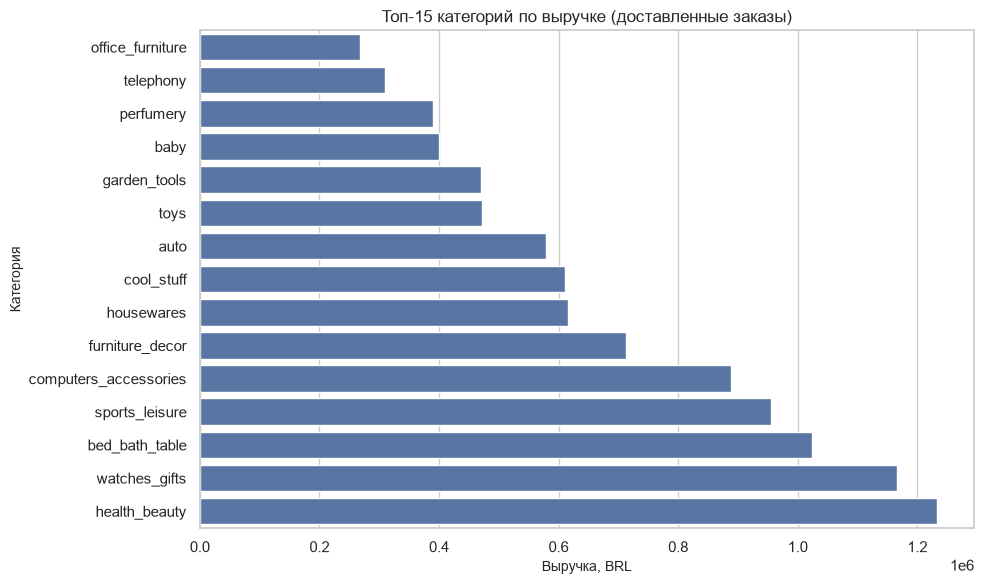


Выбросы физических характеристик (99-й перцентиль):
  weight_num     p01=     60.00  median=    700.00  p99=    22538.00  max=      40425.00
  length_num     p01=     16.00  median=     25.00  p99=      100.00  max=        105.00
  height_num     p01=      2.00  median=     13.00  p99=       69.00  max=        105.00
  width_num      p01=     11.00  median=     20.00  p99=       63.00  max=        118.00


In [15]:
print("Товаров:", len(products))
print("Без категории:", int(products["product_category_name"].isna().sum()))
print(
    "Доля без категории:",
    f"{products['product_category_name'].isna().mean() * 100:.2f}%",
)
print("Уникальных категорий в products:", products["product_category_name"].nunique())
print("Категорий в переводе:", translation["product_category_name"].nunique())

items_delivered = order_items.loc[order_items["order_id"].isin(delivered_ids)].copy()
items_categories = items_delivered.merge(
    products[
        [
            "product_id",
            "product_category_name",
            "weight_num",
            "length_num",
            "height_num",
            "width_num",
        ]
    ],
    on="product_id",
    how="left",
).merge(
    translation,
    on="product_category_name",
    how="left",
)
items_categories["category"] = (
    items_categories["product_category_name_english"]
    .fillna(items_categories["product_category_name"])
    .fillna("unknown")
)

category_revenue = (
    items_categories.groupby("category")["price_num"]
    .sum()
    .sort_values(ascending=False)
)
print("\nКатегорий в выручке:", len(category_revenue))
print("Сумма выручки по категориям:", f"{category_revenue.sum():,.2f}")
print("Топ-5:")
display(category_revenue.head(5).to_frame("revenue"))

fig, ax = plt.subplots(figsize=(10, 6))
top_categories = category_revenue.head(15).sort_values()
sns.barplot(x=top_categories.values, y=top_categories.index, ax=ax, color="#4c72b0")
ax.set_title("Топ-15 категорий по выручке (доставленные заказы)")
ax.set_xlabel("Выручка, BRL")
ax.set_ylabel("Категория")
plt.tight_layout()
plt.show()

print("\nВыбросы физических характеристик (99-й перцентиль):")
for col in ["weight_num", "length_num", "height_num", "width_num"]:
    s = products[col]
    print(
        f"  {col:14s} p01={s.quantile(0.01):>10.2f}  "
        f"median={s.median():>10.2f}  p99={s.quantile(0.99):>12.2f}  "
        f"max={s.max():>14.2f}"
    )

**Интерпретация по товарам.**
- 610 товаров (1,85%) без категории. В выручке они попадают в `unknown`;
  если просто выбросить их, сумма по категориям не сойдётся с общей.
- 2 категории (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`)
  не имеют перевода — для DWH нужен fallback на португальское название.
- В выручке 74 категории, крупнейшая — `health_beauty`. Сумма по
  категориям должна равняться общей выручке доставленных заказов.
- Вес и габариты имеют экстремальные значения; в `core` нужны numeric
  и, возможно, флаги выбросов, но не удаление без бизнес-правила.

## 9. Блок 8. Продавцы и география

Продавцов: 3095
Штатов продавцов: 23

Топ-10 продавцов по выручке (доставленные заказы):


,revenue,orders,units,seller_city,seller_state
seller_id,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,"226,987.93",1124,1148,guariba,SP
53243585a1d6dc2643021fd1853d8905,"217,940.44",348,400,lauro de freitas,BA
4a3ca9315b744ce9f8e9374361493884,"196,882.12",1772,1949,ibitinga,SP
fa1c13f2614d7b5c4749cbc52fecda94,"190,917.14",578,579,sumare,SP
7c67e1448b00f6e969d365cea6b010ab,"186,570.05",973,1355,itaquaquecetuba,SP
7e93a43ef30c4f03f38b393420bc753a,"165,981.49",319,322,barueri,SP
da8622b14eb17ae2831f4ac5b9dab84a,"159,816.87",1311,1548,piracicaba,SP
7a67c85e85bb2ce8582c35f2203ad736,"139,658.69",1145,1155,sao paulo,SP
1025f0e2d44d7041d6cf58b6550e0bfa,"138,208.56",910,1420,sao paulo,SP


Доля топ-10 продавцов в выручке: 13.27%



Штаты покупателей с наибольшей долей опозданий (>=100 заказов):

,orders,late_orders,late_pct
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22
BA,3256,457,14.04
RJ,12350,1664,13.47
TO,274,35,12.77
PA,946,117,12.37



Штаты продавцов с наибольшей долей опозданий (>=100 пар):


,order_seller_pairs,late_pairs,late_pct
seller_state,,,
MA,389,90,23.14
SP,69401,6016,8.67
RJ,4229,355,8.39
ES,310,22,7.10
PR,7556,485,6.42
DF,808,49,6.06
SC,3608,215,5.96
BA,550,32,5.82
MG,7747,432,5.58


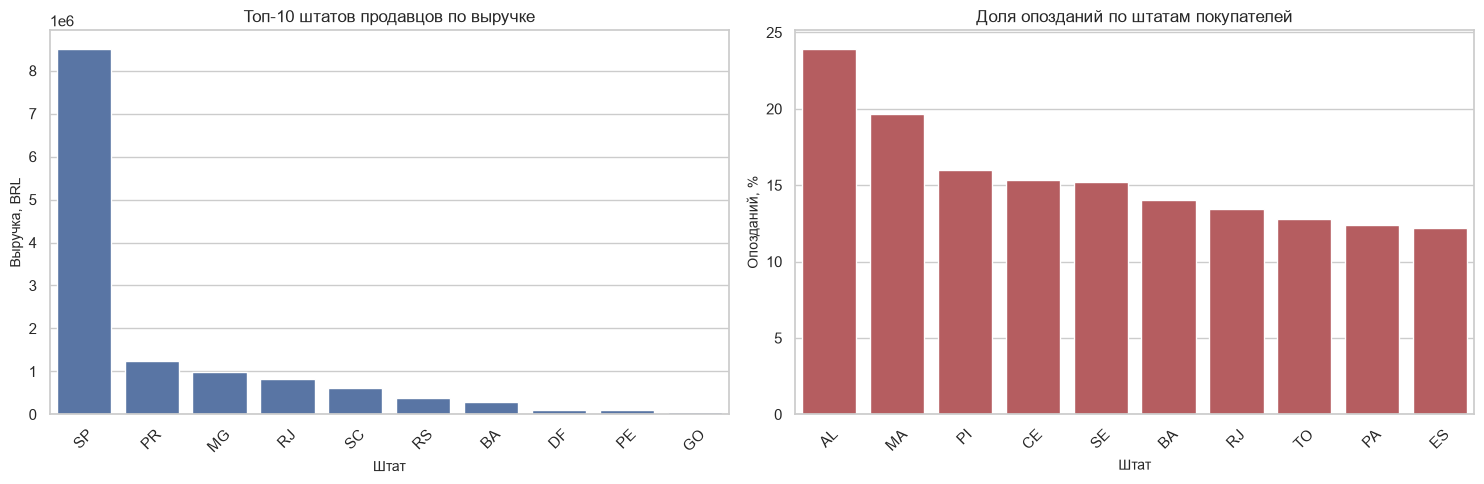

In [16]:
print("Продавцов:", len(sellers))
print("Штатов продавцов:", sellers["seller_state"].nunique())

seller_revenue = (
    items_delivered.groupby("seller_id")
    .agg(
        revenue=("price_num", "sum"),
        orders=("order_id", "nunique"),
        units=("order_item_id", "size"),
    )
    .sort_values("revenue", ascending=False)
)
seller_revenue = seller_revenue.join(
    sellers.set_index("seller_id")[["seller_city", "seller_state"]],
    how="left",
)
print("\nТоп-10 продавцов по выручке (доставленные заказы):")
display(seller_revenue.head(10))

top10_share = seller_revenue.head(10)["revenue"].sum() / seller_revenue["revenue"].sum() * 100
print(f"Доля топ-10 продавцов в выручке: {top10_share:.2f}%")

orders_delivered = orders.loc[orders["order_id"].isin(delivered_ids)].copy()
orders_delivered["late"] = (
    orders_delivered["delivered_ts"] > orders_delivered["estimated_ts"]
)
orders_delivered = orders_delivered.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
)

state_late = orders_delivered.groupby("customer_state").agg(
    orders=("order_id", "size"),
    late_orders=("late", "sum"),
)
state_late["late_pct"] = (state_late["late_orders"] / state_late["orders"] * 100).round(2)
state_late = state_late.loc[state_late["orders"] >= 100].sort_values(
    "late_pct", ascending=False
)
print("\nШтаты покупателей с наибольшей долей опозданий (>=100 заказов):")
display(state_late.head(10))

order_seller = (
    items_delivered[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(orders_delivered[["order_id", "late"]], on="order_id", how="left")
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
)
seller_state_late = order_seller.groupby("seller_state").agg(
    order_seller_pairs=("order_id", "size"),
    late_pairs=("late", "sum"),
)
seller_state_late["late_pct"] = (
    seller_state_late["late_pairs"] / seller_state_late["order_seller_pairs"] * 100
).round(2)
seller_state_late = seller_state_late.loc[
    seller_state_late["order_seller_pairs"] >= 100
].sort_values("late_pct", ascending=False)
print("\nШтаты продавцов с наибольшей долей опозданий (>=100 пар):")
display(seller_state_late.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
seller_state_revenue = (
    items_delivered.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
    .groupby("seller_state")["price_num"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
sns.barplot(
    x=seller_state_revenue.index,
    y=seller_state_revenue.values,
    ax=axes[0],
)
axes[0].set_title("Топ-10 штатов продавцов по выручке")
axes[0].set_xlabel("Штат")
axes[0].set_ylabel("Выручка, BRL")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    x=state_late.head(10).index,
    y=state_late.head(10)["late_pct"].values,
    ax=axes[1],
    color="#c44e52",
)
axes[1].set_title("Доля опозданий по штатам покупателей")
axes[1].set_xlabel("Штат")
axes[1].set_ylabel("Опозданий, %")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Интерпретация по продавцам и географии.**
- Выручка продавцов сильно концентрирована: топ-10 дают заметную долю.
  При этом выручка продавца считается только по его позициям, а не по
  всей сумме заказа — иначе мульти-вендорные заказы завысят цифры.
- Опоздания распределены по штатам неравномерно. Это аргумент за
  географическое измерение и расчёт логистических метрик по направлениям.
- `geolocation` в этой версии данных отсутствует, поэтому используем
  `customer_state`, `customer_city`, `seller_state`, `seller_city`.
  Если справочник координат появится, его нужно агрегировать до одного
  центроида на zip-префикс, иначе JOIN размножит строки.

## 10. Блок 9. Временные ряды

,orders,revenue,freight,avg_ticket
2016-09,1.00,134.97,8.49,143.46
2016-10,265.00,"40,325.11","6,165.55",175.44
2016-11,0.00,0.00,0.00,0.00
2016-12,1.00,10.90,8.72,19.62
2017-01,750.00,"111,798.36","15,684.01",169.98
2017-02,"1,653.00","234,223.40","37,015.92",164.09
2017-03,"2,546.00","359,198.85","55,132.10",162.74
2017-04,"2,303.00","340,669.68","50,142.72",169.70
2017-05,"3,546.00","489,338.25","77,513.15",159.86
2017-06,"3,135.00","421,923.37","68,127.00",156.32


Всего доставленных заказов: 96478
Выручка (price): 13,221,498.11
Доставка (freight): 2,202,965.54
Средний чек: 159.88
Месяцев с нулевой выручкой: 1

Неполные месяцы вне отчётного периода:
purchase_month
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


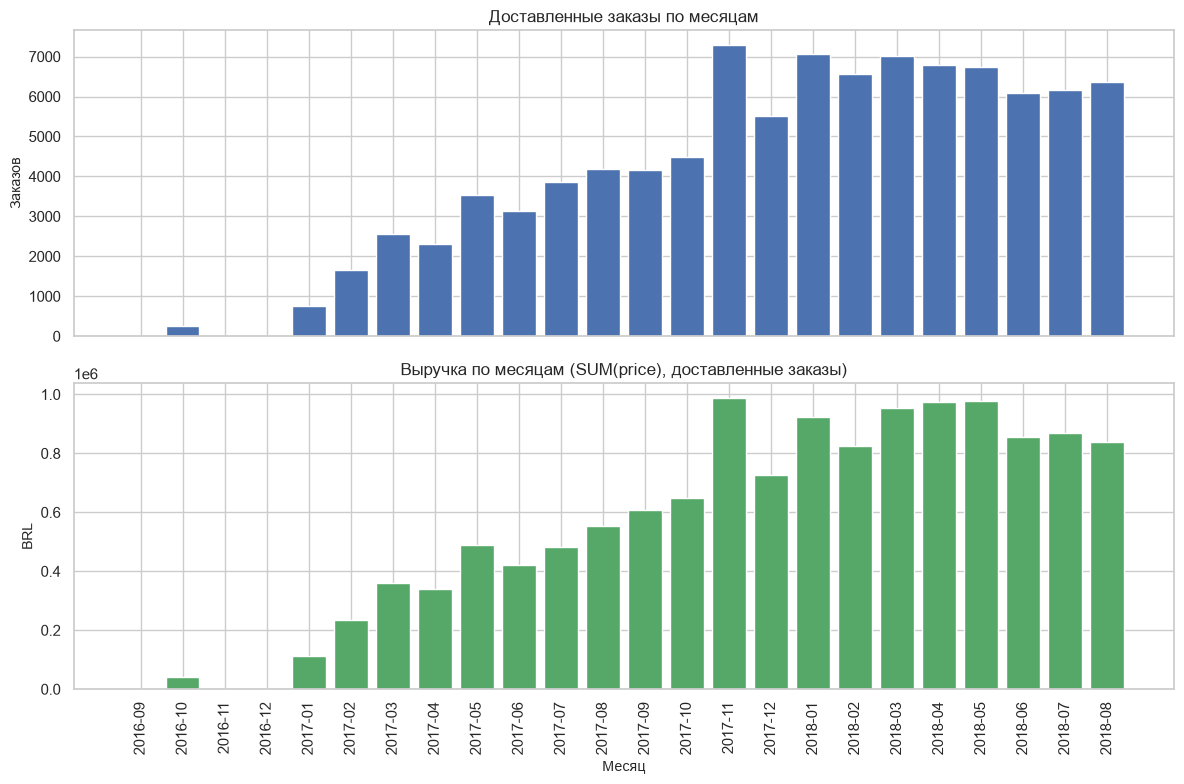

In [17]:
monthly_revenue = (
    items_delivered.merge(
        orders[["order_id", "purchase_month"]], on="order_id", how="left"
    )
    .groupby("purchase_month")
    .agg(
        revenue=("price_num", "sum"),
        freight=("freight_num", "sum"),
    )
)
monthly_orders_delivered = (
    orders_delivered.groupby("purchase_month")["order_id"].nunique()
)

monthly = pd.DataFrame(
    {
        "orders": monthly_orders_delivered,
        "revenue": monthly_revenue["revenue"],
        "freight": monthly_revenue["freight"],
    }
).reindex(month_index).fillna(0)
monthly["avg_ticket"] = np.where(
    monthly["orders"] > 0,
    (monthly["revenue"] + monthly["freight"]) / monthly["orders"],
    0,
)
monthly.index = monthly.index.astype(str)

display(monthly.round(2))

print("Всего доставленных заказов:", int(monthly["orders"].sum()))
print("Выручка (price):", f"{monthly['revenue'].sum():,.2f}")
print("Доставка (freight):", f"{monthly['freight'].sum():,.2f}")
print("Средний чек:", f"{(monthly['revenue'].sum() + monthly['freight'].sum()) / monthly['orders'].sum():,.2f}")
print("Месяцев с нулевой выручкой:", int((monthly["revenue"] == 0).sum()))

all_months = orders.groupby("purchase_month")["order_id"].nunique()
print("\nНеполные месяцы вне отчётного периода:")
print(all_months.tail(4).to_string())

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].bar(monthly.index, monthly["orders"], color="#4c72b0")
axes[0].set_title("Доставленные заказы по месяцам")
axes[0].set_ylabel("Заказов")
axes[0].tick_params(axis="x", rotation=90)

axes[1].bar(monthly.index, monthly["revenue"], color="#55a868")
axes[1].set_title("Выручка по месяцам (SUM(price), доставленные заказы)")
axes[1].set_ylabel("BRL")
axes[1].set_xlabel("Месяц")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

**Интерпретация по времени.**
- В отчётном периоде 24 месяца. Ноябрь 2016 отсутствует в исходных данных,
  поэтому после `reindex` он появится с нулём. Это важно для корректного
  отчёта: пропуск месяца не должен превращаться в пропуск строки.
- Сентябрь и октябрь 2018 — неполные месяцы, их нельзя сравнивать с
  полными месяцами без оговорки.
- Пик ноября 2017 похож на сезонную акцию (Black Friday); для DWH нужен
  календарь и, возможно, флаг промо-периода.

## 11. Блок 10. Проверка бизнес-гипотез

In [18]:
print("### Гипотеза 1. Опоздание снижает оценку")
print(f"  средняя оценка вовремя: {ontime_score:.3f}")
print(f"  средняя оценка при опоздании: {late_score:.3f}")
print(f"  разница: {late_score - ontime_score:.3f}")
print(f"  Spearman correlation: {corr:.3f}")

# Повторные покупатели и категории
repeat_ids = set(orders_per_customer[orders_per_customer > 1].index)
order_customer = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
)
items_categories = items_categories.merge(
    order_customer[["order_id", "customer_unique_id"]],
    on="order_id",
    how="left",
)
items_categories["repeat_customer"] = items_categories["customer_unique_id"].isin(repeat_ids)
items_categories["repeat_revenue"] = np.where(
    items_categories["repeat_customer"], items_categories["price_num"], 0
)
category_repeat = items_categories.groupby("category").agg(
    revenue=("price_num", "sum"),
    repeat_revenue=("repeat_revenue", "sum"),
)
category_repeat["repeat_share_pct"] = (
    category_repeat["repeat_revenue"] / category_repeat["revenue"] * 100
).round(2)
print("\n### Гипотеза 2. Повторные покупки концентрируются в категориях")
display(
    category_repeat.sort_values("revenue", ascending=False)
    .head(10)
    .round(2)
)

# Мульти-вендорность: стоимость доставки, оценки, опоздания
order_seller_count = items_delivered.groupby("order_id")["seller_id"].nunique()
order_totals = items_delivered.groupby("order_id").agg(
    items_total=("total_num", "sum"),
    freight=("freight_num", "sum"),
)
orders_hyp = orders_delivered.copy()
orders_hyp["sellers"] = orders_hyp["order_id"].map(order_seller_count).fillna(0)
orders_hyp = orders_hyp.join(order_totals, on="order_id")
orders_hyp["multi_seller"] = orders_hyp["sellers"] > 1
orders_hyp = orders_hyp.merge(
    reviews_dedup[["order_id", "review_score_num"]],
    on="order_id",
    how="left",
)
multi_stats = orders_hyp.groupby("multi_seller").agg(
    orders=("order_id", "size"),
    avg_items_total=("items_total", "mean"),
    avg_freight=("freight", "mean"),
    late_pct=("late", lambda s: s.mean() * 100),
    avg_review=("review_score_num", "mean"),
)
print("\n### Гипотеза 3. Мульти-вендорные заказы дороже по доставке и хуже по оценкам")
display(multi_stats.round(2))

# Рассрочка и чек
pay_hyp = pay_per_order.copy()
pay_hyp["installment_bucket"] = pd.cut(
    pay_hyp["max_installments"],
    bins=[-1, 1, 3, 6, 12, 24],
    labels=["1", "2-3", "4-6", "7-12", "13-24"],
)
installment_stats = pay_hyp.groupby("installment_bucket", observed=True).agg(
    orders=("pay_total", "size"),
    avg_payment=("pay_total", "mean"),
    median_payment=("pay_total", "median"),
)
print("\n### Гипотеза 4. Рассрочка связана с более высоким чеком")
display(installment_stats.round(2))

print("\n### Гипотеза 5. Географические кластеры опозданий")
display(state_late.head(5))
display(state_late.tail(5))

print("\n### Гипотеза 6. Сезонность и ноябрьский пик")
display(monthly[["orders", "revenue"]].sort_values("orders", ascending=False).head(5))

### Гипотеза 1. Опоздание снижает оценку
  средняя оценка вовремя: 4.290
  средняя оценка при опоздании: 2.270
  разница: -2.020
  Spearman correlation: -0.176

### Гипотеза 2. Повторные покупки концентрируются в категориях


,revenue,repeat_revenue,repeat_share_pct
category,,,
health_beauty,"1,233,131.72","56,169.51",4.56
watches_gifts,"1,166,176.98","53,523.74",4.59
bed_bath_table,"1,023,434.76","97,864.10",9.56
sports_leisure,"954,852.55","74,242.79",7.78
computers_accessories,"888,724.61","62,502.92",7.03
furniture_decor,"711,927.69","63,240.14",8.88
housewares,"615,628.69","36,035.33",5.85
cool_stuff,"610,204.10","24,619.04",4.03
auto,"578,966.65","23,125.33",3.99



### Гипотеза 3. Мульти-вендорные заказы дороже по доставке и хуже по оценкам


,orders,avg_items_total,avg_freight,late_pct,avg_review
multi_seller,,,,,
False,95203,158.57,22.51,8.20,4.17
True,1275,257.36,46.67,1.41,2.86



### Гипотеза 4. Рассрочка связана с более высоким чеком


...


### Гипотеза 5. Географические кластеры опозданий


,orders,late_orders,late_pct
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22


,orders,late_orders,late_pct
customer_state,,,
SP,40501,2387,5.89
MG,11354,637,5.61
PR,4923,246,5.00
AM,145,6,4.14
RO,243,7,2.88



### Гипотеза 6. Сезонность и ноябрьский пик


,orders,revenue
2017-11,"7,289.00","987,765.37"
2018-01,"7,069.00","924,645.00"
2018-03,"7,003.00","953,356.25"
2018-04,"6,798.00","973,534.09"
2018-05,"6,749.00","977,544.69"


**Что показывают проверки.**
1. Опоздание действительно связано с более низкой оценкой; направление
   связи устойчивое, хотя корреляция не означает причинность.
2. Повторные покупатели — маленькая, но ценная группа; их доля в выручке
   по категориям позволяет выбрать, где строить программы удержания.
3. Мульти-вендорные заказы — отдельный операционный сценарий: у них
   выше стоимость доставки и ниже средняя оценка, но доля опозданий
   в этой выборке не выше. Это стоит проверить отдельно: возможно,
   такие заказы чаще отменяются или собираются дольше.
4. Рассрочка используется в дорогих заказах; для витрин это признак
   платёжеспособного сегмента, но не причинный фактор.
5. Опоздания по штатам различаются; направление «продавец → покупатель»
   стоит вынести в отдельную аналитическую витрину.
6. Ноябрьский пик и неполные месяцы требуют календарного измерения и
   аккуратной интерпретации.

## 12. Инженерные выводы и рекомендации для DWH

### 12.1. Типы данных для `core`

| Сущность | Поле | Тип |
|---|---|---|
| Заказы | `order_id`, `customer_id` | `varchar` |
| Заказы | `order_status` | `varchar` |
| Заказы | даты жизненного цикла | `timestamp`, nullable |
| Позиции | `order_item_id` | `integer` |
| Позиции | `price`, `freight_value` | `numeric(12,2)` |
| Платежи | `payment_sequential` | `integer` |
| Платежи | `payment_value` | `numeric(12,2)` |
| Платежи | `payment_installments` | `integer` |
| Отзывы | `review_score` | `integer` |
| Товары | вес, габариты | `numeric` |

Идентификаторы — `varchar`, деньги — `numeric`, не `float`. Даты доставки
nullable: отсутствие даты означает «событие не произошло», а не ошибку.

### 12.2. Гранулярность фактов

- `fct_order_items` — одна строка = одна позиция заказа.
  Ключ `(order_id, order_item_id)`. Здесь живут `price`, `freight_value`,
  `product_id`, `seller_id`. Выручка продавца и категории считается здесь.
- `fct_orders` — одна строка = один заказ. Здесь живут статус, даты,
  сумма платежей, флаг опоздания. Средний чек считается здесь.
- `fct_payments` — одна строка = один платёж.
  Ключ `(order_id, payment_sequential)`.
- `fct_reviews` — одна строка = один отзыв.
  Ключ `(review_id, order_id)`; для одной оценки на заказ — дедупликация
  по `review_answer_timestamp`.

**Нельзя смешивать уровни:** средний чек по строкам позиций даст 139,97
вместо 159,88; средняя цена товара без доставки даст 123,75.

### 12.3. Измерения

- `dim_customers` — ключ `customer_unique_id`, атрибуты города/штата;
- `dim_products` — `product_id`, категория, вес, габариты;
- `dim_sellers` — `seller_id`, город, штат;
- `dim_category` — перевод категорий + `unknown`;
- `dim_date` — календарь, включая месяцы без заказов.

### 12.4. Пропуски и качество

- Даты доставки — nullable, без default-значений.
- Категория товара — `unknown`-член измерения, не NULL в факте.
- `payment_installments = 0` — трактовать как 1 или `unknown`.
- Дубли отзывов — составной ключ или дедупликация.
- `customers.customer_unique_id` — ключ покупателя; `customer_id` — ключ
  заказа/строки.
- После каждого JOIN в ETL сравнивать количество строк до/после.

### 12.5. Контрольные суммы

- выручка за сентябрь 2016 — август 2018: `13 221 498.11` (`SUM(price)`,
  только `delivered`);
- топ-продавец: `226 987.93`;
- средний чек: `159.88` (`price + freight` на доставленный заказ);
- покупателей: `96 096`, повторных: `2 997` (`3.12%`);
- категорий: `74`, крупнейшая: `1 233 131.72`, сумма: `13 221 498.11`.

### 12.6. Бизнес-гипотезы для дальнейшей проверки

1. Опоздание доставки снижает оценку; эффект сильнее при задержке > 7 дней.
2. Повторные покупки сконцентрированы в отдельных категориях и штатах,
   несмотря на низкий общий repeat rate.
3. Мульти-вендорные заказы имеют более высокую стоимость доставки и
   более низкую удовлетворённость.
4. Рассрочка связана с более высоким чеком; кредитные карты доминируют
   в дорогих заказах.
5. Есть географические кластеры опозданий; направление «продавец →
   покупатель» влияет на срок сильнее, чем просто штат.
6. Сезонность и ноябрьский пик 2017 требуют календарного измерения
   и отдельного флага промо-периода.

### 12.7. Что проверить на защите

- Почему выручка — это `SUM(price)`, а средний чек — `price + freight`.
- Почему `customer_unique_id`, а не `customer_id`.
- Что произойдёт с отчётом, если месяц без заказов не появится.
- Сколько строк теряется на каждом JOIN.
- Как обрабатываются заказы без позиций/платежей и отзывы-дубли.

## 13. Финальные контрольные проверки

In [19]:
def check(name, actual, expected, tol=0.01):
    if isinstance(expected, (int, float, np.integer, np.floating)):
        ok = bool(np.isclose(actual, expected, atol=tol, rtol=0))
    else:
        ok = actual == expected
    return {
        "проверка": name,
        "факт": actual,
        "ожидание": expected,
        "статус": "PASS" if ok else "FAIL",
    }


checks = []
checks.append(check("Всего строк в 8 файлах", sum(len(df) for df in tables.values()), 550759))
checks.append(check("orders", len(orders), 99441))
checks.append(check("order_items", len(order_items), 112650))
checks.append(check("order_payments", len(order_payments), 103886))
checks.append(check("order_reviews", len(order_reviews), 99224))
checks.append(check("products", len(products), 32951))
checks.append(check("sellers", len(sellers), 3095))
checks.append(check("translation", len(translation), 71))

revenue_control = float(items_delivered["price_num"].sum())
checks.append(check("Выручка, SUM(price), delivered", revenue_control, 13221498.11))
checks.append(check("Топ-продавец, revenue", float(seller_revenue["revenue"].iloc[0]), 226987.93))
checks.append(
    check(
        "Средний чек, (price+freight)/orders",
        float(items_delivered["total_num"].sum() / len(delivered_ids)),
        159.88,
    )
)
checks.append(check("Уникальные покупатели", customers["customer_unique_id"].nunique(), 96096))
checks.append(check("Повторные покупатели", repeat_customers, 2997))
checks.append(check("Доля повторных, %", round(repeat_share, 2), 3.12))
checks.append(check("Категорий в выручке", len(category_revenue), 74))
checks.append(check("Топ-категория, revenue", float(category_revenue.iloc[0]), 1233131.72))
checks.append(check("Сумма по категориям", float(category_revenue.sum()), 13221498.11))
checks.append(check("Месяцев в отчёте", len(monthly), 24))
checks.append(check("Месяцев с нулевой выручкой", int((monthly["revenue"] == 0).sum()), 1))
checks.append(check("Сиротские строки, всего", int(ri["сиротских_строк"].sum()), 0))
checks.append(check("Полные дубли, всего", int(sum(df.duplicated().sum() for df in tables.values())), 0))
checks.append(
    check(
        "Дубли (review_id, order_id)",
        int(order_reviews.duplicated(["review_id", "order_id"]).sum()),
        0,
    )
)

checks_df = pd.DataFrame(checks)
display(checks_df)

if (checks_df["статус"] == "FAIL").any():
    print("\nВНИМАНИЕ: не все контрольные проверки прошли.")
else:
    print("\nВсе контрольные проверки прошли.")

,проверка,факт,ожидание,статус
0,Всего строк в 8 файлах,"550,759.00","550,759.00",PASS
1,orders,"99,441.00","99,441.00",PASS
2,order_items,"112,650.00","112,650.00",PASS
3,order_payments,"103,886.00","103,886.00",PASS
4,order_reviews,"99,224.00","99,224.00",PASS
5,products,"32,951.00","32,951.00",PASS
6,sellers,"3,095.00","3,095.00",PASS
7,translation,71.00,71.00,PASS
8,"Выручка, SUM(price), delivered","13,221,498.11","13,221,498.11",PASS
9,"Топ-продавец, revenue","226,987.93","226,987.93",PASS



Все контрольные проверки прошли.


## 14. Итог

Notebook последовательно проверяет:

- размерности и типы;
- пропуски и пустые значения;
- полные дубли и дубли по бизнес-ключам;
- ссылочную целостность;
- аномалии дат и чисел;
- воронку статусов, сроки доставки и опоздания;
- `customer_id` vs `customer_unique_id` и repeat rate;
- гранулярность позиций и мульти-вендорность;
- сверку платежей с позициями;
- отзывы и их связь с задержкой;
- категории, товары и продавцов;
- месячную динамику и сезонность;
- контрольные суммы из `docs/tasks.md`.

**Главный вывод для DWH:** строить модель нужно на двух уровнях —
заказ и позиция заказа, — с отдельными фактами для платежей и отзывов.
Выручка, средний чек и оплаты — разные метрики; их нельзя считать
на одном уровне и нельзя смешивать. Пропуски дат и категорий должны
быть явно описаны в модели, а не «залечены» случайными default-значениями.